<a href="https://colab.research.google.com/github/Anish-185/GANs/blob/main/GANs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch: 200
Epoch: 400
Epoch: 600
Epoch: 800
Epoch: 1000


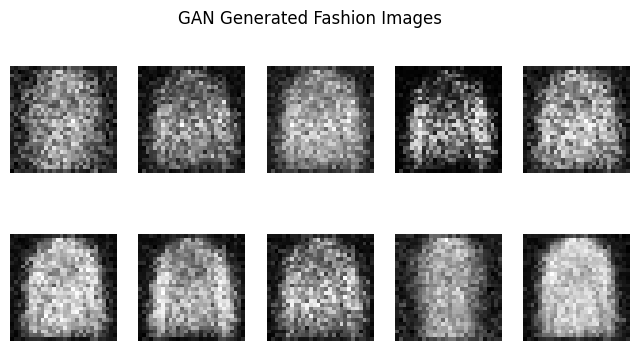

In [1]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Load Fashion-MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

# Normalize images
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train.reshape(-1, 784)

# Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(100,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(784, activation="tanh")
])

# Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

discriminator.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# GAN
discriminator.trainable = False
gan = tf.keras.Sequential([generator, discriminator])
gan.compile(optimizer="adam", loss="binary_crossentropy")

# Training
for epoch in range(1000):
    idx = np.random.randint(0, len(x_train), 32)
    real = x_train[idx]

    noise = np.random.normal(0, 1, (32, 100))
    fake = generator.predict(noise, verbose=0)

    discriminator.trainable = True
    discriminator.train_on_batch(real, np.ones((32, 1)))
    discriminator.train_on_batch(fake, np.zeros((32, 1)))

    discriminator.trainable = False
    noise = np.random.normal(0, 1, (32, 100))
    gan.train_on_batch(noise, np.ones((32, 1)))

    if (epoch + 1) % 200 == 0:
        print("Epoch:", epoch + 1)

# Generate synthetic fashion images
noise = np.random.normal(0, 1, (10, 100))
images = generator.predict(noise, verbose=0)

# Display output
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("GAN Generated Fashion Images")
plt.show()
